In [ ]:
import os
from PIL import Image

# Ensure Pillow is installed
try:
    from PIL import Image
except ImportError:
    %pip install Pillow
    from PIL import Image

In [ ]:
def generate_multiple_copies_per_image(source_dir, num_additional_copies):
    """
    Generates a specified number of additional copies for each image in the source directory.

    Args:
        source_dir (str): The path to the directory containing the images.
        num_additional_copies (int): The number of additional copies to create for each image.
    """
    if not os.path.exists(source_dir):
        print(f"Error: Directory not found at {source_dir}")
        return

    print(f"Generating {num_additional_copies} additional copies for each image in '{source_dir}'...")

    # Filter for actual files and ignore directories
    files = [f for f in os.listdir(source_dir) if os.path.isfile(os.path.join(source_dir, f))]
    original_file_count = len(files)
    print(f"Found {original_file_count} original images in '{source_dir}'.")

    if original_file_count == 0:
        print(f"No images found in '{source_dir}' to copy.")
        return

    for original_filename in files:
        original_path = os.path.join(source_dir, original_filename)
        name, ext = os.path.splitext(original_filename)

        try:
            img = Image.open(original_path)
            # Create num_additional_copies for each original image
            for i in range(1, num_additional_copies + 1):
                new_filename = f"{name}_copy_{i:03d}{ext}" # e.g., image_name_copy_001.jpg
                new_path = os.path.join(source_dir, new_filename)
                img.save(new_path)
            # print(f"  Generated {num_additional_copies} copies for '{original_filename}'.")
        except Exception as e:
            print(f"Error processing image '{original_filename}': {e}")

    print(f"Finished generating copies for images in '{source_dir}'.")
    print(f"Total files in '{source_dir}' after copying: {len(os.listdir(source_dir))}")


# Define the base training directory
train_base_dir = '/content/drive/MyDrive/fruits/train'
apple_train_dir = os.path.join(train_base_dir, 'apple')
banana_train_dir = os.path.join(train_base_dir, 'banana')
guava_train_dir = os.path.join(train_base_dir, 'guava')

# Number of additional copies per image
NUM_COPIES = 100

print("--- Processing Bike images ---")
generate_multiple_copies_per_image(apple_train_dir, NUM_COPIES)

print("\n--- Processing Car images ---")
generate_multiple_copies_per_image(banana_train_dir, NUM_COPIES)

print("--- Processing Bike images ---")
generate_multiple_copies_per_image(guava_train_dir, NUM_COPIES)


print("\nImage copying process complete for both 'Bike' and 'Car' training folders.")

--- Processing Bike images ---
Generating 100 additional copies for each image in '/content/drive/MyDrive/fruits/train/apple'...
Found 1 original images in '/content/drive/MyDrive/fruits/train/apple'.
Finished generating copies for images in '/content/drive/MyDrive/fruits/train/apple'.
Total files in '/content/drive/MyDrive/fruits/train/apple' after copying: 101

--- Processing Car images ---
Generating 100 additional copies for each image in '/content/drive/MyDrive/fruits/train/banana'...
Found 1 original images in '/content/drive/MyDrive/fruits/train/banana'.
Finished generating copies for images in '/content/drive/MyDrive/fruits/train/banana'.
Total files in '/content/drive/MyDrive/fruits/train/banana' after copying: 101
--- Processing Bike images ---
Generating 100 additional copies for each image in '/content/drive/MyDrive/fruits/train/guava'...
Found 1 original images in '/content/drive/MyDrive/fruits/train/guava'.
Finished generating copies for images in '/content/drive/MyDrive/

In [ ]:
from posixpath import split
import os
import shutil
import random

original_dataset_dir = "/content/drive/MyDrive/fruits/train"
base_dir = "/content/fruits/dataset_split"

train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")

# Create folders
for folder in ["train/apple", "train/banana","train/guava", "test/apple", "test/banana","test/guava"]:
    os.makedirs(os.path.join(base_dir, folder), exist_ok=True)

# Split function
def split_data(class_name, split_size=0.8):
    source_dir = os.path.join(original_dataset_dir, class_name)
    images = os.listdir(source_dir)
    random.seed(42)
    random.shuffle(images)

    split_index = int(len(images) * split_size)

    train_images = images[:split_index]
    test_images = images[split_index:]

    for img in train_images:
        shutil.copy(os.path.join(source_dir, img),
                    os.path.join(train_dir, class_name, img))

    for img in test_images:
        shutil.copy(os.path.join(source_dir, img),
                    os.path.join(test_dir, class_name, img))

# Split both classes
split_data("apple")
split_data("banana")
split_data("guava")
print("Dataset split completed!")

Dataset split completed!


In [ ]:
import os
train_labels=os.listdir('/content/fruits/dataset_split/train')
test_labels=os.listdir('/content/fruits/dataset_split/test')
print(train_labels)
print(test_labels)

['apple', 'guava', 'banana']
['apple', 'guava', 'banana']


In [ ]:
import os
from PIL import Image

def convert_images_to_png(directory_path):
    """
    Converts all supported image files in the given directory and its subdirectories to PNG format.
    Original non-PNG files are removed after successful conversion.

    Args:
        directory_path (str): The path to the directory to process.
    """
    if not os.path.exists(directory_path):
        print(f"Error: Directory not found at {directory_path}")
        return

    print(f"Starting image conversion to PNG in '{directory_path}'...")
    supported_extensions = ['.jpg', '.jpeg', '.gif', '.bmp'] # .png is excluded as it's the target format

    for root, _, files in os.walk(directory_path):
        for filename in files:
            file_path = os.path.join(root, filename)
            name, ext = os.path.splitext(filename)

            # Convert extension to lowercase for case-insensitive comparison
            ext_lower = ext.lower()

            if ext_lower == '.png':
                print(f"  Skipping '{filename}': already in PNG format.")
                continue

            # Check if it's a supported image format that needs conversion
            if ext_lower in supported_extensions:
                try:
                    with Image.open(file_path) as img:
                        new_filename = f"{name}.png"
                        new_file_path = os.path.join(root, new_filename)
                        img.save(new_file_path, 'PNG')
                        print(f"  Converted '{filename}' to '{new_filename}'.")

                    # Remove the original file after successful conversion
                    os.remove(file_path)
                    print(f"  Removed original file: '{filename}'.")
                except Exception as e:
                    print(f"  Error processing '{filename}': {e}")
            else:
                print(f"  Skipping '{filename}': not a recognized image format for conversion (extension: {ext}).")

    print(f"Finished image conversion process for '{directory_path}'.")

In [ ]:
base_path = '/content/fruits/dataset_split'
train_path = os.path.join(base_path, 'train')
test_path = os.path.join(base_path, 'test')

# The two classes
classes = ['apple', 'guava', 'banana']

print("--- Converting Training Directories to PNG ---")
for cls in classes:
    train_class_dir = os.path.join(train_path, cls)
    convert_images_to_png(train_class_dir)

print("\n--- Converting Testing Directories to PNG ---")
for cls in classes:
    test_class_dir = os.path.join(test_path, cls)
    convert_images_to_png(test_class_dir)

print("\nAll specified directories have been processed for PNG conversion.")

--- Converting Training Directories to PNG ---
Starting image conversion to PNG in '/content/fruits/dataset_split/train/apple'...
  Converted 'istockphoto-476752624-612x612_copy_099.jpg' to 'istockphoto-476752624-612x612_copy_099.png'.
  Removed original file: 'istockphoto-476752624-612x612_copy_099.jpg'.
  Converted 'istockphoto-476752624-612x612_copy_001.jpg' to 'istockphoto-476752624-612x612_copy_001.png'.
  Removed original file: 'istockphoto-476752624-612x612_copy_001.jpg'.
  Converted 'istockphoto-476752624-612x612_copy_021.jpg' to 'istockphoto-476752624-612x612_copy_021.png'.
  Removed original file: 'istockphoto-476752624-612x612_copy_021.jpg'.
  Converted 'istockphoto-476752624-612x612_copy_054.jpg' to 'istockphoto-476752624-612x612_copy_054.png'.
  Removed original file: 'istockphoto-476752624-612x612_copy_054.jpg'.
  Converted 'istockphoto-476752624-612x612_copy_011.jpg' to 'istockphoto-476752624-612x612_copy_011.png'.
  Removed original file: 'istockphoto-476752624-612x612_

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 20

train_dir = "/content/fruits/dataset_split/train"
test_dir = "/content/fruits/dataset_split/test"

train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

model = models.Sequential([
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),


    layers.Dense(3, activation='softmax') # Changed from 1 to 3 units for 3 classes
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS
)


Found 240 files belonging to 3 classes.
Found 63 files belonging to 3 classes.
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 995ms/step - accuracy: 0.5521 - loss: 1.1638 - val_accuracy: 1.0000 - val_loss: 0.0079
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 486ms/step - accuracy: 1.0000 - loss: 0.0160 - val_accuracy: 1.0000 - val_loss: 7.9473e-08
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 258ms/step - accuracy: 0.9901 - loss: 0.0088 - val_accuracy: 1.0000 - val_loss: 3.9736e-08
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 215ms/step - accuracy: 1.0000 - loss: 5.4978e-06 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 264ms/step - accuracy: 1.0000 - loss: 7.1190e-05 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 243ms/step - accuracy: 1.0000 - loss: 1.9928e-05 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 375ms/step - accuracy: 1.0000 - loss: 1.6040e-04 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 257ms/step - accuracy: 1.0000 - loss: 3.0743e-05

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


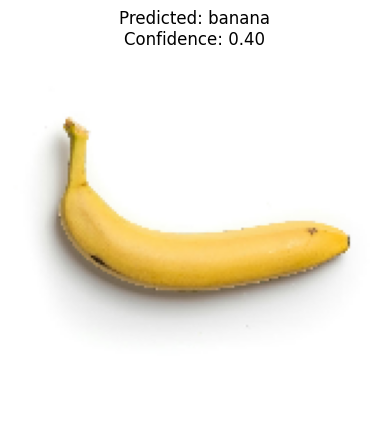

Raw Probability: 0.40341642
Predicted Class: banana


In [31]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
IMG_SIZE = 160
class_names = ['apple', 'guava', 'banana']
img_path = "/content/fruits/dataset_split/test/banana/photo-1587132137056-bfbf0166836e_copy_001_copy_001.jpg"   # put your image path here

img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0
prediction = model.predict(img_array)

probability = prediction[0]
predicted_index = np.argmax(probability)
predicted_class = class_names[predicted_index]
confidence = probability[predicted_index]


plt.imshow(img)
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}")
plt.axis("off")
plt.show()
print("Raw Probability:", probability)
print("Predicted Class:", predicted_class)

### Dataset and execution notes
- Update dataset paths to match the folders available in your environment before running.
- The original CNN architecture and training workflow have been retained.
- Results depend on dataset quality, class balance, folder order, and training configuration.